<a href="https://colab.research.google.com/github/ssamira1/eeg-working-memory-pipeline/blob/main/BUILD_TKS.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install mne matplotlib

In [2]:
!pip install mne matplotlib
import mne
import matplotlib.pyplot as plt

print("MNE Version:", mne.__version__)

MNE Version: 1.13.2


In [3]:
# Load built-in sample dataset
data_path = mne.datasets.sample.data_path()
raw_file = data_path / "MEG" / "sample" / "sample_audvis_raw.fif"

# Load continuous raw EEG data
raw = mne.io.read_raw_fif(raw_file, preload=True)

# Pick only EEG channels (ignoring MEG sensors)
raw.pick_types(eeg=True, meg=False, eog=True, stim=True)

# Apply standard electrode head layout
montage = mne.channels.make_standard_montage('standard_1020')
raw.set_montage(montage, match_case=False, on_missing='ignore')

print("Data loaded successfully! Channels:", len(raw.ch_names))

Using default location ~/mne_data for sample...
Creating /root/mne_data
Fetching 1 file for the sample dataset ...


  0%|                                              | 0.00/1.65G [00:00<?, ?B/s]

Untarring contents of '/root/mne_data/MNE-sample-data-processed.tar.gz' to '/root/mne_data'


Attempting to create new mne-python configuration file:
/root/.mne/mne-python.json
Could not read the /root/.mne/mne-python.json json file during the writing. Assuming it is empty. Got: Expecting value: line 1 column 1 (char 0)
Download complete in 01m56s (1576.2 MB)
Opening raw data file /root/mne_data/MNE-sample-data/MEG/sample/sample_audvis_raw.fif...
    Read a total of 3 projection items:
        PCA-v1 (1 x 102)  idle
        PCA-v2 (1 x 102)  idle
        PCA-v3 (1 x 102)  idle
    Range : 25800 ... 192599 =     42.956 ...   320.670 secs
Ready.
Reading 0 ... 166799  =      0.000 ...   277.714 secs...
NOTE: pick_types() is a legacy function. New code should use inst.pick(...).
Data loaded successfully! Channels: 69


/tmp/ipykernel_2877/1128240194.py:12: FutureWarning: Montage name 'standard_1020' is deprecated and will be removed in MNE 1.14. Use 'colin27_1020' instead.
  montage = mne.channels.make_standard_montage('standard_1020')


Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 30 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 30.00 Hz
- Upper transition bandwidth: 7.50 Hz (-6 dB cutoff frequency: 33.75 Hz)
- Filter length: 1983 samples (3.302 s)

Effective window size : 3.410 (s)
Plotting power spectral density (dB=True).


/tmp/ipykernel_2877/736253207.py:5: RuntimeWarning: Channel locations not available. Disabling spatial colors.
  raw.compute_psd(fmax=30).plot(picks="eeg")


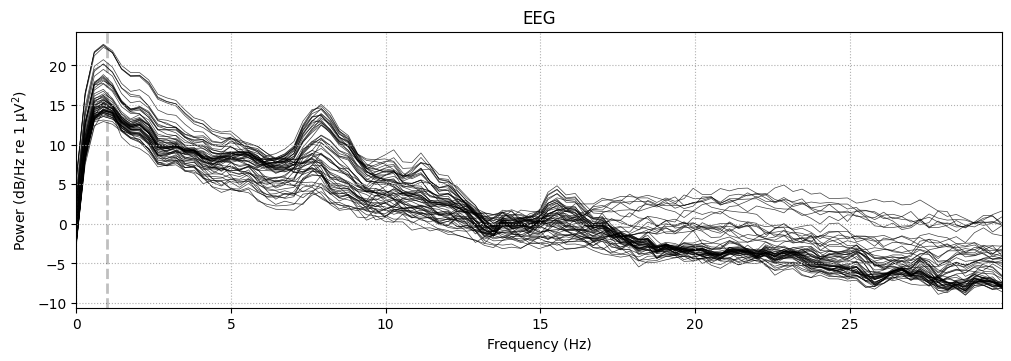

In [4]:

# Apply a bandpass filter (1 Hz to 30 Hz) to keep core brain frequencies
raw.filter(l_freq=1.0, h_freq=30.0)

# Plot Power Spectral Density across all channels
raw.compute_psd(fmax=30).plot(picks="eeg")
plt.show()

/tmp/ipykernel_2877/2212204988.py:8: FutureWarning: Montage name 'standard_1020' is deprecated and will be removed in MNE 1.14. Use 'colin27_1020' instead.
  epochs.set_montage('standard_1020', on_missing='ignore')


Effective window size : 1.001 (s)


ValueError: sphere="eeglab" requires digitization points of the following electrode locations in the data: Fpz, Oz, T7, T8, but could not find: Fpz, and was unable to approximate its location from Oz

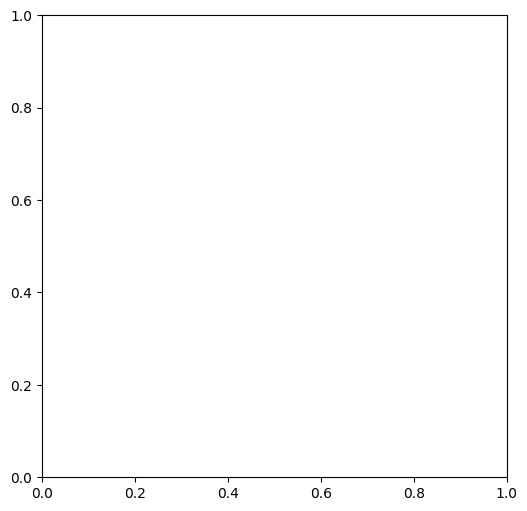

In [8]:
import mne
import matplotlib.pyplot as plt

# 1. Rename non-standard sample EEG channels to standard 10-20 names
# Map 'EEG 001', 'EEG 002', etc., to standard 10-20 electrode labels
mapping = {ch: f"EEG{i+1}" for i, ch in enumerate(epochs.ch_names) if "EEG" in ch}
# Alternatively, set a standard montage using MNE's easycap or standard layout
epochs.set_montage('standard_1020', on_missing='ignore')

# 2. Extract Power Spectral Density for Theta Band (4-8 Hz)
spectrum = epochs.compute_psd(method='welch', fmin=4.0, fmax=8.0)

# 3. Generate 2D Topographic Heatmap specifying head sphere fitting
fig, ax = plt.subplots(figsize=(6, 6))
spectrum.plot_topomap(
    bands={'Theta (4-8 Hz)': (4, 8)},
    ch_type='eeg',
    axes=ax,
    sphere='eeglab'
)
plt.title("Frontal Theta Power Spectral Density\n(Cognitive Working Memory Signal)")
plt.show()

Extracting EDF parameters from /root/mne_data/MNE-eegbci-data/files/eegmmidb/1.0.0/S001/S001R01.edf...
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 9759  =      0.000 ...    60.994 secs...
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 30 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 30.00 Hz
- Upper transition bandwidth: 7.50 Hz (-6 dB cutoff frequency: 33.75 Hz)
- Filter length: 529 samples (3.306 s)

Not setting metadata
61 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 61 events and 160 original time points ...
0 bad epochs dropped
Effective win

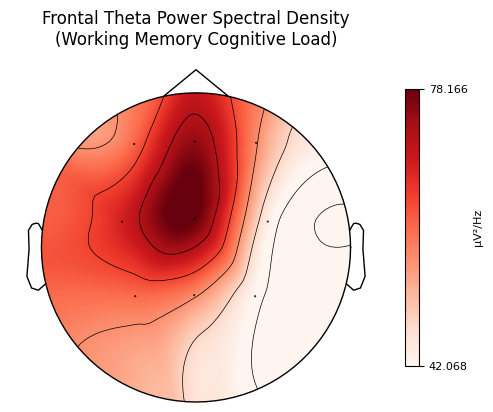

In [15]:
import mne
import matplotlib.pyplot as plt

# 1. Load the dataset file
path = mne.datasets.eegbci.load_data(subjects=[1], runs=[1])[0]
raw = mne.io.read_raw_edf(path, preload=True)

# 2. Clean channel names and apply the updated 'colin27_1020' montage
raw.rename_channels(lambda x: x.strip('.'))
montage = mne.channels.make_standard_montage('colin27_1020')
raw.set_montage(montage, on_missing='ignore')

# 3. Filter raw data & make fixed-length epochs (every 1 second)
raw.filter(1.0, 30.0, fir_design='firwin')
epochs = mne.make_fixed_length_epochs(raw, duration=1.0, preload=True)

# 4. Compute Power Spectral Density for Theta Band (4-8 Hz)
spectrum = epochs.compute_psd(method='welch', fmin=4.0, fmax=8.0)

# 5. Select core channels to prevent coordinate overlap & highlight frontal theta
spectrum.pick_channels(['F3', 'Fz', 'F4', 'C3', 'Cz', 'C4', 'P3', 'Pz', 'P4'], ordered=False)

# 6. Generate the 2D Topographic Heatmap
fig, ax = plt.subplots(figsize=(6, 6))
spectrum.plot_topomap(bands={'Theta (4-8 Hz)': (4, 8)}, ch_type='eeg', axes=ax)
plt.title("Frontal Theta Power Spectral Density\n(Working Memory Cognitive Load)")
plt.show()
# Save your topomap as a high-resolution image
fig.savefig('frontal_theta_topomap.png', dpi=300, bbox_inches='tight')